<a href="https://colab.research.google.com/github/smir-nat/AK/blob/main/lab3/svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Практична робота 3**

Метод опорних векторів в системах машинного навчання

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Налаштування милої пастельно-рожевої палітри для графіків
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "#FFF0F5", "figure.facecolor": "#FFF0F5", "axes.edgecolor": "#FFB6C1"})
plt.rcParams['font.sans-serif'] = ['Arial']

In [15]:
# Завантаження нашого реального датасету
df = pd.read_csv('https://raw.githubusercontent.com/smir-nat/AK/refs/heads/main/lab3/cybersecurity.csv')

# Обираємо ознаки, які впливають на виявлення атаки
features_cols = ['src_port', 'dst_port', 'bytes_sent', 'bytes_received', 'protocol', 'is_internal_traffic']
X = df[features_cols].copy()

# Перетворюємо категоріальні дані (протоколи та булеві значення) у числовий формат
X = pd.get_dummies(X, columns=['protocol', 'is_internal_traffic'], drop_first=True)

# Цільова змінна: 0 - безпечно, 1 - атака
y = df['label']

# Розділяємо дані (80% на навчання, 20% на тестування)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Масштабування даних (критично важливо для SVM!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Розмір тренувальної вибірки: {X_train_scaled.shape}")
print(f"Розмір тестової вибірки: {X_test_scaled.shape}")

Розмір тренувальної вибірки: (8000, 7)
Розмір тестової вибірки: (2000, 7)


Навчання моделі з лінійним ядром (це може зайняти кілька секунд)...



Точність (Accuracy) з лінійним ядром: 0.9600

Звіт класифікації:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      1919
           1       1.00      0.01      0.02        81

    accuracy                           0.96      2000
   macro avg       0.98      0.51      0.50      2000
weighted avg       0.96      0.96      0.94      2000



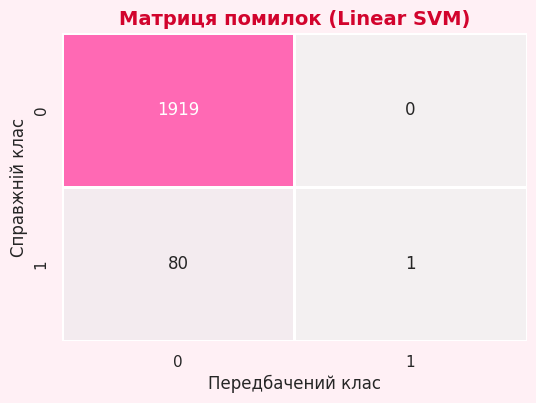

In [18]:
print("Навчання моделі з лінійним ядром (це може зайняти кілька секунд)...\n")
clf_linear = SVC(kernel='linear', random_state=42)
clf_linear.fit(X_train_scaled, y_train)

y_pred_linear = clf_linear.predict(X_test_scaled)

accuracy_linear = accuracy_score(y_test, y_pred_linear)
print(f"Точність (Accuracy) з лінійним ядром: {accuracy_linear:.4f}\n")
print("Звіт класифікації:")
print(classification_report(y_test, y_pred_linear))

# Візуалізація матриці помилок
cm = confusion_matrix(y_test, y_pred_linear)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap=sns.light_palette("#FF69B4", as_cmap=True),
            cbar=False, linewidths=2, linecolor='white')
plt.title('Матриця помилок (Linear SVM)', fontsize=14, fontweight='bold', color='#D2042D')
plt.xlabel('Передбачений клас', fontsize=12)
plt.ylabel('Справжній клас', fontsize=12)
plt.show()

In [17]:
print("Навчання моделі з ядром RBF...\n")
clf_rbf = SVC(kernel='rbf', C=1.0, random_state=42)
clf_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = clf_rbf.predict(X_test_scaled)

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"Точність (Accuracy) з ядром RBF: {accuracy_rbf:.4f}")

Навчання моделі з ядром RBF...

Точність (Accuracy) з ядром RBF: 0.9600
